### Import Required Libraries
Importing all the libraries needed for data handling, visualization, preprocessing, model building, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

### Load the Dataset
Loading the bike sharing dataset (day.csv) into a DataFrame and checking its shape.

In [2]:
df=pd.read_csv("day.csv")
print("Shape of dataset:",df.shape)

Shape of dataset: (731, 16)


### Preview the Data
Displaying the first five rows to get a quick look at the columns and values.

In [3]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Dataset Info
Checking column data types and non-null counts to understand the structure of the dataset.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


### Statistical Summary
Getting the mean, min, max, and other statistics for the numerical columns.

In [5]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


### Column Names
Listing all column names present in the dataset.

In [6]:
print(df.columns)

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')


### Missing Values Check
Checking each column for missing values.

In [7]:
missing_values=df.isnull().sum()
print(missing_values)

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


### Duplicate Rows Check
Checking whether any duplicate rows exist in the dataset.

In [8]:
duplicate_count=df.duplicated().sum()
print("Number of duplicate rows:",duplicate_count)

Number of duplicate rows: 0


### Convert Date Column
Converting the date column from text to a proper datetime format.

In [9]:
df["dteday"]=pd.to_datetime(df["dteday"])
print(df["dteday"].dtype)

datetime64[us]


### Boxplots for Weather Variables
Plotting boxplots for temp, atemp, hum, and windspeed together in one row to check for outliers.

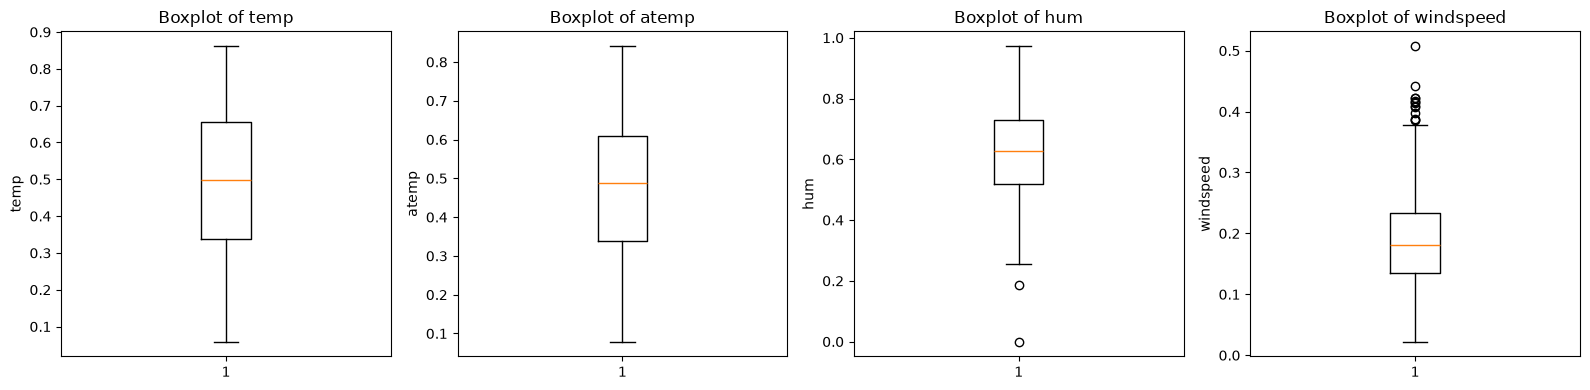

In [10]:
numerical_columns=["temp","atemp","hum","windspeed"]
fig, axes=plt.subplots(1,4,figsize=(16,4))
for ax, column in zip(axes, numerical_columns):
    ax.boxplot(df[column])
    ax.set_title("Boxplot of "+column)
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()

### Distribution of Total Bike Rentals
Plotting the distribution of the target variable (cnt) using bars.

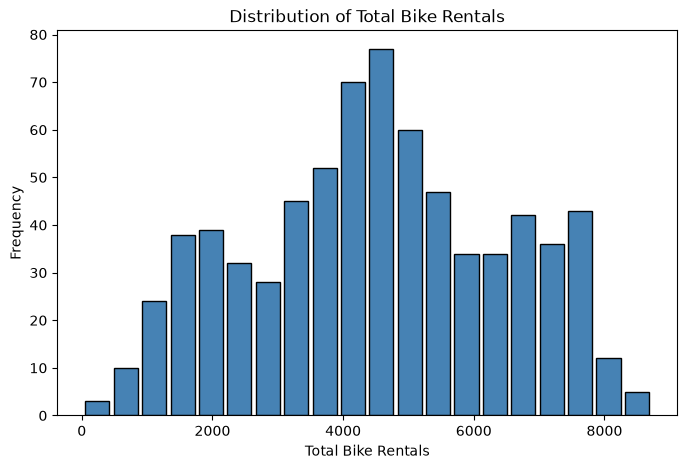

In [11]:
bin_edges=np.linspace(df["cnt"].min(),df["cnt"].max(),21)
counts,edges=np.histogram(df["cnt"],bins=bin_edges)
bin_centers=(edges[:-1]+edges[1:])/2
bar_width=(edges[1]-edges[0])*0.85
plt.figure(figsize=(8,5))
plt.bar(bin_centers,counts,width=bar_width,color="steelblue",edgecolor="black")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.title("Distribution of Total Bike Rentals")
plt.show()

### Bike Rental Demand Over Time
Plotting how total daily rentals change over the two-year period.

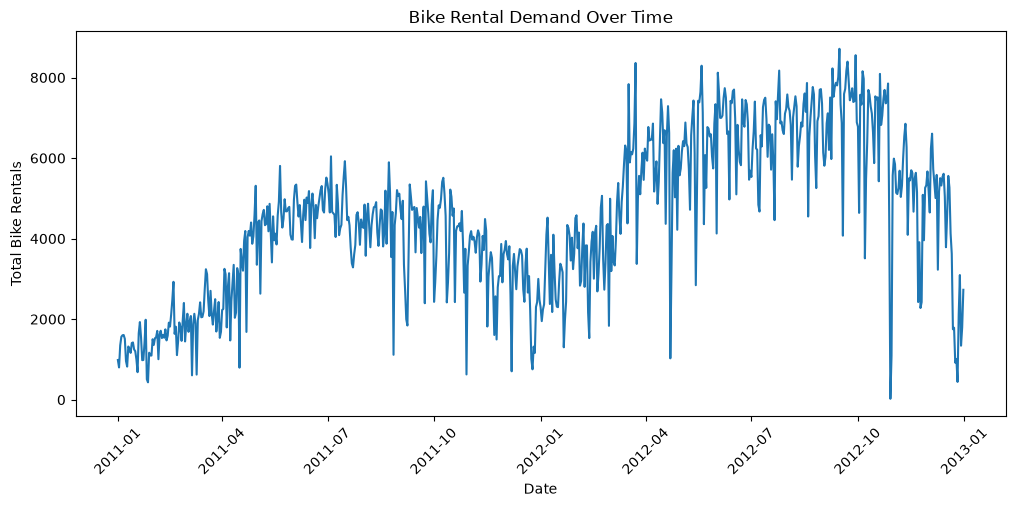

In [12]:
plt.figure(figsize=(12,5))
plt.plot(df["dteday"],df["cnt"])
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")
plt.title("Bike Rental Demand Over Time")
plt.xticks(rotation=45)
plt.show()

### Correlation Matrix
Plotting a heatmap showing correlation between all numerical variables, with the values shown on each cell.

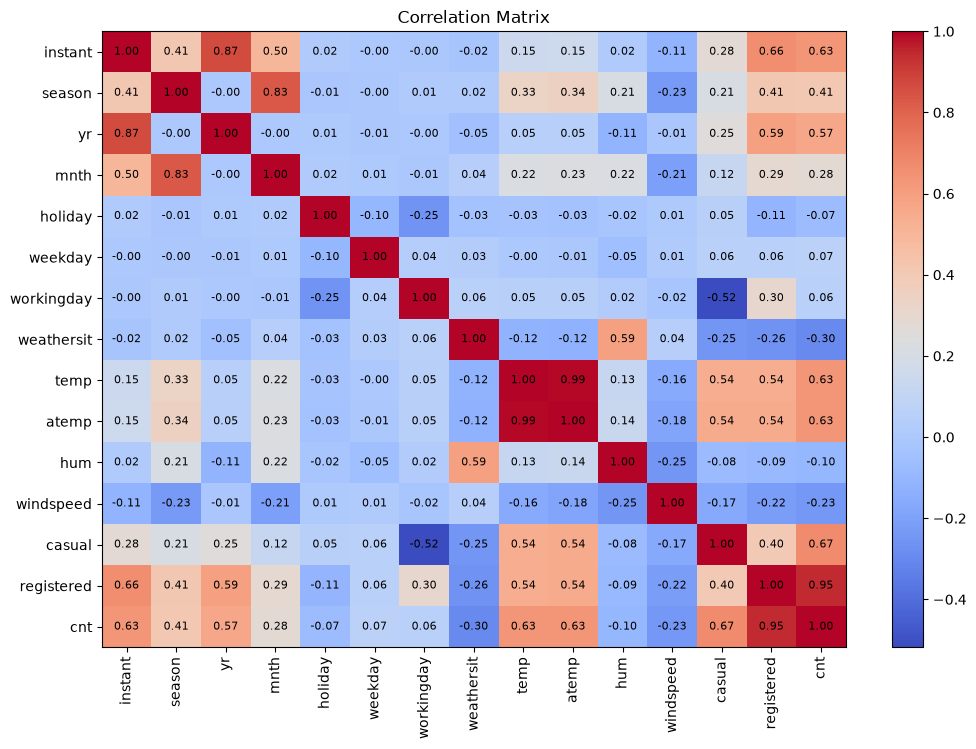

In [13]:
correlation = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
for (i, j), value in np.ndenumerate(correlation.values):
    plt.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation Matrix")
plt.show()

### Correlation with Target
Displaying correlation of each numerical feature with the target variable, sorted in descending order.

In [14]:
target_correlation=correlation["cnt"].sort_values(ascending=False)
print(target_correlation)

cnt           1.000000
registered    0.945517
casual        0.672804
atemp         0.631066
instant       0.628830
temp          0.627494
yr            0.566710
season        0.406100
mnth          0.279977
weekday       0.067443
workingday    0.061156
holiday      -0.068348
hum          -0.100659
windspeed    -0.234545
weathersit   -0.297391
Name: cnt, dtype: float64


### Define Target and Features
Setting cnt as the target and dropping columns that shouldn't be used for prediction (casual, registered, instant, dteday).

In [15]:
target="cnt"
columns_to_drop=[
    "cnt",
    "casual",
    "registered",
    "instant",
    "dteday"
]
x=df.drop(columns=columns_to_drop)
y=df[target]
print("Feature shape:",x.shape)
print("Target shape:",y.shape)

Feature shape: (731, 11)
Target shape: (731,)


### Final Feature List
Displaying the features that will be used for training the models.

In [16]:
print("Features used by the model:")
print(x.columns)

Features used by the model:
Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed'],
      dtype='str')


### Train-Test Split
Splitting the data chronologically into training and testing sets, since this is time-based data.

In [17]:
split_index=int(len(x)*0.8)
x_train=x.iloc[:split_index]
x_test=x.iloc[split_index:]
y_train=y.iloc[:split_index]
y_test=y.iloc[split_index:]
print("Training data:",x_train.shape)
print("Testing data:",x_test.shape)

Training data: (584, 11)
Testing data: (147, 11)


### Categorical and Numerical Features
Separating the features into categorical and numerical groups for preprocessing.

In [18]:
categorical_features=[
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]
numerical_features=[
    "temp",
    "atemp",
    "hum",
    "windspeed",
]
print("Categorical features:")
print(categorical_features)
print("\nNumerical features:")
print(numerical_features)

Categorical features:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']

Numerical features:
['temp', 'atemp', 'hum', 'windspeed']


### One-Hot Encoding
Converting categorical features into one-hot encoded columns and aligning train/test columns.

In [19]:
x_train=pd.get_dummies(
    x_train,
    columns=categorical_features,
    dtype=int
)
x_test=pd.get_dummies(
    x_test,
    columns=categorical_features,
    dtype=int
)
x_test=x_test.reindex(
    columns=x_train.columns,
    fill_value=0
)
print("Features after one-hot encoding:", x_train.shape[1])

Features after one-hot encoding: 36


### Feature Scaling
Scaling the numerical features using StandardScaler.

In [20]:
scaler=StandardScaler()
x_train[numerical_features]=scaler.fit_transform(
    x_train[numerical_features]
)
x_test[numerical_features]=scaler.transform(
    x_test[numerical_features]
)

### Standard statistical significance(p-value) decision framework:
low R2, high P-value --- worst scenario;

high R2, high P-value --- model is worthless;

low R2, low P-value --- better than not having a model;

high R2, low P-value --- best scenario;

### Remove Dummy Variable Trap
Dropping one dummy column per categorical feature before running the statistical significance test.

In [21]:
cols_to_drop=[]
for feat in categorical_features:
    dummy_cols=[c for c in x_train.columns if c.startswith(feat + "_")]
    if dummy_cols:
        cols_to_drop.append(dummy_cols[0])
x_train_stats=x_train.drop(columns=cols_to_drop)
print("Dropped columns:",cols_to_drop)
print("Remaining columns:",x_train_stats.shape[1])

Dropped columns: ['season_1', 'yr_0', 'mnth_1', 'holiday_0', 'weekday_0', 'workingday_0', 'weathersit_1']
Remaining columns: 29


### OLS Regression and P-Value Check
Fitting an OLS regression using statsmodels to check the R2 and p-value for statistical significance.

In [22]:
import statsmodels.api as sm
cols_to_drop=(
    [c for c in x_train_stats.columns if c.startswith("season_")]
    + ["temp","workingday_1"]
)
x_train_final=x_train_stats.drop(columns=cols_to_drop)
X_train_sm=sm.add_constant(x_train_final.astype(float))
model_sm=sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                     129.0
Date:                Tue, 01 Sep 2026   Prob (F-statistic):          5.32e-210
Time:                        11:01:59   Log-Likelihood:                -4653.7
No. Observations:                 584   AIC:                             9357.
Df Residuals:                     559   BIC:                             9467.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         2071.5285    165.623     12.507   

High R² + Low p-value → **Best case**(scenario)

### Define the Models
Setting up the five regression models to be compared.

In [23]:
models={
    "Linear Regression":LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

### Train the Models
Training all five models on the training data.

In [24]:
trained_models={}
for name, model in models.items():
    print("Training:", name)
    model.fit(x_train, y_train)
    trained_models[name]=model

Training: Linear Regression
Training: Ridge Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting


### Evaluate the Models
Evaluating all models on the test data using MAE, MSE, RMSE, and R2 Score.

In [25]:
results=[]
for name, model in trained_models.items():
    predictions=model.predict(x_test)
    mae=mean_absolute_error(y_test,predictions)
    mse=mean_squared_error(y_test,predictions)
    rmse=np.sqrt(mse)
    r2=r2_score(y_test,predictions)
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })
results_df=pd.DataFrame(results)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,803.625377,1.215863e+06,1102.661997,0.654014
1,Ridge Regression,810.563367,1.216944e+06,1103.151973,0.653707
2,Decision Tree,1067.292517,1.911867e+06,1382.702776,0.455960
3,Random Forest,1031.398027,1.519454e+06,1232.661445,0.567625
4,Gradient Boosting,931.842645,1.197298e+06,1094.211308,0.659297


### Sort by RMSE
Sorting the results table by RMSE to see the best-performing model.

In [26]:
results_sorted=results_df.sort_values(
    by="RMSE"
)
results_sorted

,Model,MAE,MSE,RMSE,R2 Score
4,Gradient Boosting,931.842645,1.197298e+06,1094.211308,0.659297
0,Linear Regression,803.625377,1.215863e+06,1102.661997,0.654014
1,Ridge Regression,810.563367,1.216944e+06,1103.151973,0.653707
3,Random Forest,1031.398027,1.519454e+06,1232.661445,0.567625
2,Decision Tree,1067.292517,1.911867e+06,1382.702776,0.455960


### Sort by R2 Score
Sorting the results table by R2 Score to see the best-performing model.

In [27]:
r2_comparison=results_df.sort_values(
    by="R2 Score",
    ascending=False
)
r2_comparison

,Model,MAE,MSE,RMSE,R2 Score
4,Gradient Boosting,931.842645,1.197298e+06,1094.211308,0.659297
0,Linear Regression,803.625377,1.215863e+06,1102.661997,0.654014
1,Ridge Regression,810.563367,1.216944e+06,1103.151973,0.653707
3,Random Forest,1031.398027,1.519454e+06,1232.661445,0.567625
2,Decision Tree,1067.292517,1.911867e+06,1382.702776,0.455960


### RMSE Comparison Chart
Plotting a bar chart comparing RMSE across all models.

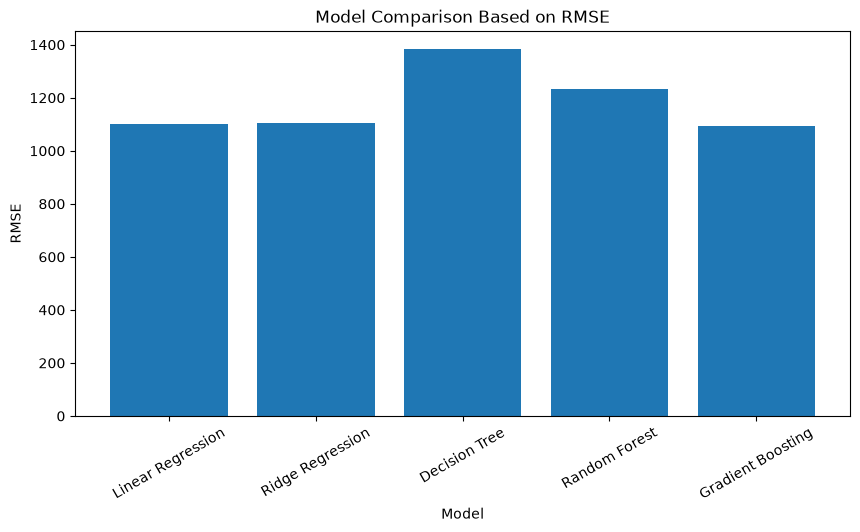

In [28]:
plt.figure(figsize=(10,5))
plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Model Comparison Based on RMSE")
plt.xticks(rotation=30)
plt.show()

### R2 Score Comparison Chart
Plotting a bar chart comparing R2 Score across all models.

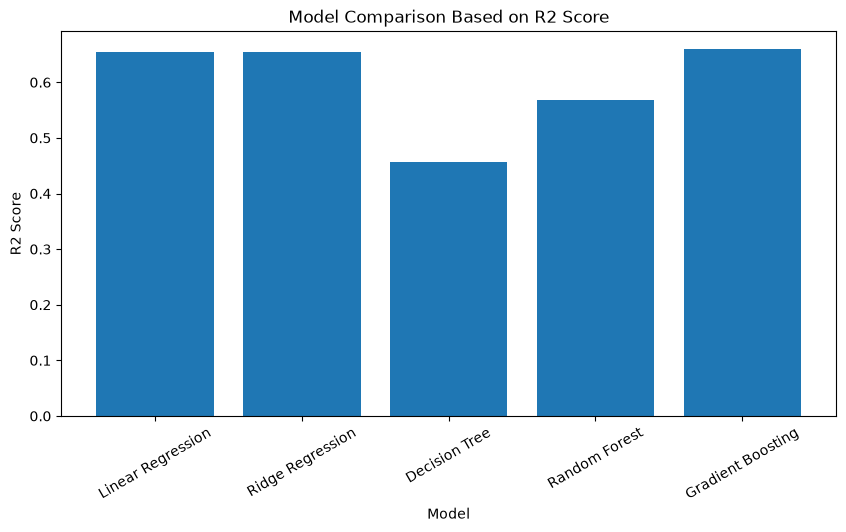

In [29]:
plt.figure(figsize=(10,5))
plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Model Comparison Based on R2 Score")
plt.xticks(rotation=30)
plt.show()

### Time Series Cross-Validation
Setting up TimeSeriesSplit for hyperparameter tuning.

In [30]:
tscv=TimeSeriesSplit(n_splits=5)
print("Time Series Cross Validation created.")

Time Series Cross Validation created.


### Hyperparameter Grid
Defining the hyperparameter values to search over for the Random Forest model.

In [31]:
rf_parameters = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 1.0]
}

### Hyperparameter Search
Running RandomizedSearchCV to find the best Random Forest hyperparameters.

In [32]:
rf_model=RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)
rf_search=RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_parameters,
    n_iter=20,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1
)
rf_search.fit(x_train, y_train)
print("Hyperparameter tuning completed.")

Hyperparameter tuning completed.


### Best Hyperparameters
Displaying the best hyperparameter combination found.

In [33]:
print("Best Random Forest parameters:")
print(rf_search.best_params_)

Best Random Forest parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 10}


### Best Cross-Validation RMSE
Displaying the RMSE achieved by the best hyperparameter combination.

In [34]:
best_cv_rmse=-rf_search.best_score_
print("Best Cross-Validation RMSE:", best_cv_rmse)

Best Cross-Validation RMSE: 1283.1933551830903


### Evaluate Tuned Random Forest
Evaluating the tuned Random Forest model on the test data.

In [35]:
rf_predictions=rf_search.predict(x_test)
rf_mae=mean_absolute_error(
    y_test,
    rf_predictions
)
rf_mse=mean_squared_error(
    y_test,
    rf_predictions
)
rf_rmse=np.sqrt(rf_mse)
rf_r2=r2_score(
    y_test,
    rf_predictions
)
print("Tuned Random Forest Results")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

Tuned Random Forest Results
MAE : 1041.5589885730733
MSE : 1542826.3463460263
RMSE: 1242.1056099809011
R2  : 0.5609737562034841


### Update Comparison Table
Adding the tuned Random Forest results to the model comparison table.

In [36]:
tuned_result=pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "MAE": [rf_mae],
    "MSE": [rf_mse],
    "RMSE": [rf_rmse],
    "R2 Score": [rf_r2]
})
final_comparison=pd.concat(
    [results_df,tuned_result],
    ignore_index=True
)
final_comparison.sort_values(
    by="RMSE"
)

,Model,MAE,MSE,RMSE,R2 Score
4,Gradient Boosting,931.842645,1.197298e+06,1094.211308,0.659297
0,Linear Regression,803.625377,1.215863e+06,1102.661997,0.654014
1,Ridge Regression,810.563367,1.216944e+06,1103.151973,0.653707
3,Random Forest,1031.398027,1.519454e+06,1232.661445,0.567625
5,Tuned Random Forest,1041.558989,1.542826e+06,1242.105610,0.560974
2,Decision Tree,1067.292517,1.911867e+06,1382.702776,0.455960


### Select Best Model
Selecting the model with the lowest RMSE as the best model.

In [37]:
best_model_name=final_comparison.loc[
    final_comparison["RMSE"].idxmin(),
    "Model"
]
print("Best model based on RMSE:")
print(best_model_name)

Best model based on RMSE:
Gradient Boosting


### Best Model Performance
Displaying the performance metrics of the selected best model.

In [38]:
best_model_result = final_comparison[
    final_comparison["Model"] == best_model_name
]
best_model_result

,Model,MAE,MSE,RMSE,R2 Score
4,Gradient Boosting,931.842645,1.197298e+06,1094.211308,0.659297


### Actual vs Predicted Rentals
Plotting actual vs predicted values along with a best-fit line to visually check prediction accuracy.

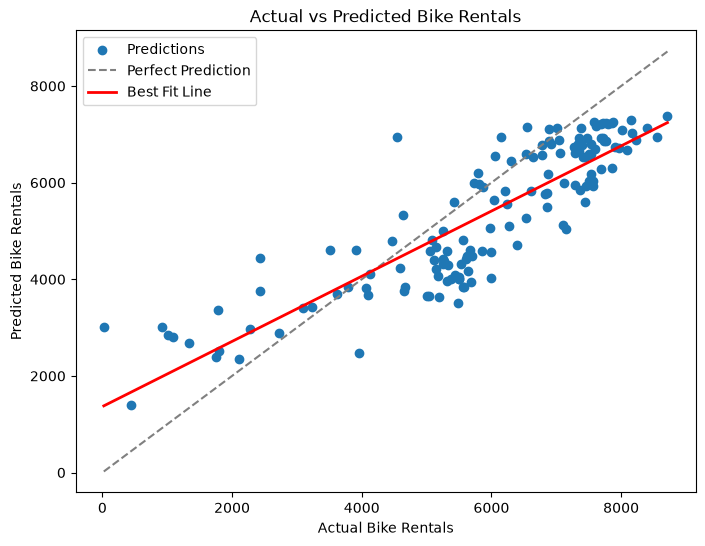

In [39]:
if best_model_name=="Tuned Random Forest":
    final_model=rf_search
else:
    final_model=trained_models[best_model_name]
final_predictions=final_model.predict(x_test)

plt.figure(figsize=(8,6))
plt.scatter(y_test,final_predictions,label="Predictions")

minimum=min(y_test.min(),final_predictions.min())
maximum=max(y_test.max(),final_predictions.max())
plt.plot([minimum,maximum],[minimum,maximum],linestyle="--",color="gray",label="Perfect Prediction")

slope,intercept=np.polyfit(y_test,final_predictions,1)
x_fit=np.array([y_test.min(),y_test.max()])
y_fit=slope*x_fit+intercept
plt.plot(x_fit,y_fit,color="red",linewidth=2,label="Best Fit Line")

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals")
plt.legend()
plt.show()

### Prediction Error Distribution
Plotting the distribution of prediction errors (actual minus predicted).

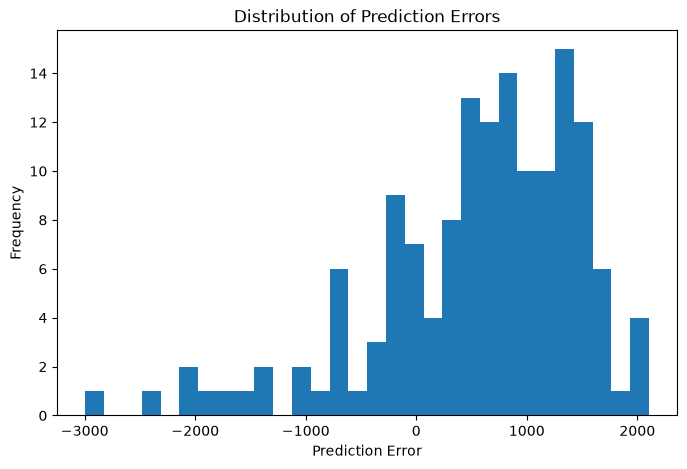

In [40]:
errors = y_test - final_predictions
plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30)
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.show()

### New Unseen Observation
Creating a new sample observation to test the final model.

In [41]:
new_data=pd.DataFrame({
    "season": [2],
    "yr": [1],
    "mnth": [6],
    "holiday": [0],
    "weekday": [3],
    "workingday": [1],
    "weathersit": [1],
    "temp": [0.65],
    "atemp": [0.62],
    "hum": [0.55],
    "windspeed": [0.20]
})
new_data

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,2,1,6,0,3,1,1,0.65,0.62,0.55,0.2


### Preprocess New Data
Applying the same encoding and scaling steps used on the training data.

In [42]:
new_data=pd.get_dummies(
    new_data,
    columns=categorical_features,
    dtype=int
)
new_data=new_data.reindex(
    columns=x_train.columns,
    fill_value=0
)
new_data[numerical_features]=scaler.transform(
    new_data[numerical_features]
)

### Predict for New Data
Predicting the bike rental count for the new observation.

In [43]:
new_prediction=final_model.predict(new_data)
print(
    "Predicted total bike rentals:",
    round(new_prediction[0])
)

Predicted total bike rentals: 7046


### Check Predictions on Random Observations
Testing the final model on a few random rows from the test set to see how close predictions are to actual values.

In [44]:
random_sample=x_test.sample(n=5, random_state=42)
actual_values=y_test.loc[random_sample.index]
predicted_values=final_model.predict(random_sample)
comparison=pd.DataFrame({
    "Actual":actual_values.values,
    "Predicted":predicted_values.round()
})
comparison["Difference"]=comparison["Actual"]-comparison["Predicted"]
comparison

,Actual,Predicted,Difference
0,5170,4070.0,1100.0
1,7393,6769.0,624.0
2,1787,3372.0,-1585.0
3,5255,4994.0,261.0
4,5499,4055.0,1444.0


### Save Results
Saving the final model comparison results to a CSV file.

In [45]:
final_comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)
print("Model comparison results saved.")

Model comparison results saved.


### Project Summary

**Best predictive model:** Gradient Boosting  

**Statistical significance (p-value) check:**  
- R² = 0.85 (high)  
- p-value ≈ 0.000 (very low)  

**Result:** High R² + Low p-value → **Best case — the model is statistically significant and worth using(best scenario).**